## 1. 기본 feature

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# 데이터 불러오기
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

# 사용할 변수
features = [
    'data_channel', 'weekday', 'title_sentiment_polarity', 'abs_title_sentiment_polarity',
    'num_imgs', 'num_videos', 'n_tokens_content', 'n_tokens_title'
]

# 타겟 변수
target = 'y'

In [ ]:
# 1. 결측치 처리
def preprocess(df):
    df = df.copy()

    # 1. data_channel: 결측치 'Other' 또는 'unknown'
    df['data_channel'] = df['data_channel'].fillna('Other')

    # 2. title_sentiment_polarity, abs_title_sentiment_polarity: 0.0으로
    df['title_sentiment_polarity'] = df['title_sentiment_polarity'].fillna(0.0)
    df['abs_title_sentiment_polarity'] = df['abs_title_sentiment_polarity'].fillna(0.0)

    # 3. num_imgs, num_videos: 0으로
    df['num_imgs'] = df['num_imgs'].fillna(0)
    df['num_videos'] = df['num_videos'].fillna(0)

    # 4. weekday: mode로
    mode_weekday = df['weekday'].mode()[0]
    df['weekday'] = df['weekday'].fillna(mode_weekday)

    # 5. n_tokens_content, n_tokens_title: 평균 또는 중앙값
    df['n_tokens_content'] = df['n_tokens_content'].fillna(df['n_tokens_content'].median())
    df['n_tokens_title'] = df['n_tokens_title'].fillna(df['n_tokens_title'].median())

    return df

train_df = preprocess(train_df)
test_df = preprocess(test_df)

# 범주형 인코딩
le_channel = LabelEncoder()
le_weekday = LabelEncoder()

train_df['data_channel'] = le_channel.fit_transform(train_df['data_channel'])
test_df['data_channel'] = le_channel.transform(test_df['data_channel'])

train_df['weekday'] = le_weekday.fit_transform(train_df['weekday'])
test_df['weekday'] = le_weekday.transform(test_df['weekday'])

# 모델 입력
X = train_df[features]
y = train_df[target]

# train/val 분할
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 학습
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# 예측 및 평가 (validation set 기준)
y_pred = clf.predict(X_val)
y_prob = clf.predict_proba(X_val)[:, 1]

acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)

print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
print(f"Final Score (avg): {(acc + f1 + auc)/3:.4f}")

Accuracy: 0.5874, F1 Score: 0.5863, AUC: 0.6158
Final Score (avg): 0.5965


## 2. 기본 feature + 'n_unique_tokens', 'n_non_stop_words', 'num_hrefs', 'num_self_hrefs'

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# 데이터 불러오기
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

# 사용할 feature 리스트
features = [
    'data_channel', 'weekday',
    'title_sentiment_polarity', 'abs_title_sentiment_polarity',
    'num_imgs', 'num_videos',
    'n_tokens_content', 'n_tokens_title',
    'n_unique_tokens', 'n_non_stop_words',
    'num_hrefs', 'num_self_hrefs'
]

target = 'y'  # 타겟 변수

# 결측치 처리
def preprocess(df):
    df = df.copy()

    # 기본 feature
    df['data_channel'] = df['data_channel'].fillna('Other')
    df['title_sentiment_polarity'] = df['title_sentiment_polarity'].fillna(0.0)
    df['abs_title_sentiment_polarity'] = df['abs_title_sentiment_polarity'].fillna(0.0)
    df['num_imgs'] = df['num_imgs'].fillna(0)
    df['num_videos'] = df['num_videos'].fillna(0)
    mode_weekday = df['weekday'].mode()[0]
    df['weekday'] = df['weekday'].fillna(mode_weekday)
    df['n_tokens_content'] = df['n_tokens_content'].fillna(df['n_tokens_content'].median())
    df['n_tokens_title'] = df['n_tokens_title'].fillna(df['n_tokens_title'].median())

    # 추가 feature 처리
    df['n_unique_tokens'] = df['n_unique_tokens'].fillna(df['n_unique_tokens'].median()) # 중앙값
    df['n_non_stop_words'] = df['n_non_stop_words'].fillna(df['n_non_stop_words'].median()) # 중앙값
    df['num_hrefs'] = df['num_hrefs'].fillna(0) # 0
    df['num_self_hrefs'] = df['num_self_hrefs'].fillna(0) # 0

    return df

# 전처리 적용
train_df = preprocess(train_df)
test_df = preprocess(test_df)

# 범주형 인코딩
le_channel = LabelEncoder()
le_weekday = LabelEncoder()

train_df['data_channel'] = le_channel.fit_transform(train_df['data_channel'])
test_df['data_channel'] = le_channel.transform(test_df['data_channel'])

train_df['weekday'] = le_weekday.fit_transform(train_df['weekday'])
test_df['weekday'] = le_weekday.transform(test_df['weekday'])

# 학습 및 평가
X = train_df[features]
y = train_df[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)
y_prob = clf.predict_proba(X_val)[:, 1]

# 예측 및 평가 (validation set 기준)
acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)

print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
print(f"Final Score (avg): {(acc + f1 + auc) / 3:.4f}")

Accuracy: 0.6068, F1 Score: 0.6019, AUC: 0.6368
Final Score (avg): 0.6152


## 3. 기본 feature + 'num_keywords', 'self_reference_avg_sharess','kw_max_max', 'n_non_stop_unique_tokens'

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# 데이터 불러오기
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

# 사용할 feature 리스트 (제목 & SNS 확산 기반 조합)
features = [
    'data_channel', 'weekday',
    'title_sentiment_polarity', 'abs_title_sentiment_polarity',
    'num_imgs', 'num_videos',
    'n_tokens_content', 'n_tokens_title',
    'num_keywords', 'self_reference_avg_sharess',
    'kw_max_max', 'n_non_stop_unique_tokens'
]

target = 'y'

# 전처리 함수
def preprocess(df):
    df = df.copy()

    # 기본 feature 처리
    df['data_channel'] = df['data_channel'].fillna('Other')
    df['title_sentiment_polarity'] = df['title_sentiment_polarity'].fillna(0.0)
    df['abs_title_sentiment_polarity'] = df['abs_title_sentiment_polarity'].fillna(0.0)
    df['num_imgs'] = df['num_imgs'].fillna(0)
    df['num_videos'] = df['num_videos'].fillna(0)
    mode_weekday = df['weekday'].mode()[0]
    df['weekday'] = df['weekday'].fillna(mode_weekday)
    df['n_tokens_content'] = df['n_tokens_content'].fillna(df['n_tokens_content'].median())
    df['n_tokens_title'] = df['n_tokens_title'].fillna(df['n_tokens_title'].median())

    return df

# 확장 전처리 (조합2 feature 포함)
def preprocess_v3(df):
    df = preprocess(df)

    df['num_keywords'] = df['num_keywords'].fillna(0)
    df['self_reference_avg_sharess'] = df['self_reference_avg_sharess'].fillna(df['self_reference_avg_sharess'].median())
    df['kw_max_max'] = df['kw_max_max'].fillna(df['kw_max_max'].median())
    df['n_non_stop_unique_tokens'] = df['n_non_stop_unique_tokens'].fillna(df['n_non_stop_unique_tokens'].median())

    return df

# 전처리 적용
train_df = preprocess_v3(train_df)
test_df = preprocess_v3(test_df)

# 범주형 인코딩
le_channel = LabelEncoder()
le_weekday = LabelEncoder()

train_df['data_channel'] = le_channel.fit_transform(train_df['data_channel'])
test_df['data_channel'] = le_channel.transform(test_df['data_channel'])

train_df['weekday'] = le_weekday.fit_transform(train_df['weekday'])
test_df['weekday'] = le_weekday.transform(test_df['weekday'])

# 모델 학습 및 평가
X = train_df[features]
y = train_df[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)
y_prob = clf.predict_proba(X_val)[:, 1]

# 예측 및 평가 (validation set 기준)
acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)

print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
print(f"Final Score (avg): {(acc + f1 + auc) / 3:.4f}")

Accuracy: 0.6232, F1 Score: 0.6221, AUC: 0.6651
Final Score (avg): 0.6368


## 4. GridSearchCV로 최적 파라미터 조합 찾고 모델 훈련 후 성능 출력

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. 데이터 로드
train_df = pd.read_csv("train.csv")

# 2. 전처리 함수
def preprocessing(df):
    df = df.copy()

    # 결측치 처리
    df['title_sentiment_polarity'] = df['title_sentiment_polarity'].fillna(0.0)
    df['abs_title_sentiment_polarity'] = df['abs_title_sentiment_polarity'].fillna(0.0)
    df['n_tokens_title'] = df['n_tokens_title'].fillna(df['n_tokens_title'].median())
    df['n_tokens_content'] = df['n_tokens_content'].fillna(df['n_tokens_content'].median())
    df['num_imgs'] = df['num_imgs'].fillna(0)
    df['num_videos'] = df['num_videos'].fillna(0)

    # 키워드 관련 열 평균 대체
    kw_cols = [col for col in df.columns if col.startswith('kw_')]
    for col in kw_cols:
        df[col] = df[col].fillna(df[col].mean())

    # 로그 변환 (극단값 완화)
    for col in ['self_reference_avg_sharess', 'num_hrefs', 'num_keywords']:
        df[col] = df[col].fillna(df[col].mean())
        df[col] = np.log1p(df[col])

    # 범주형 → one-hot + 주말 변수 추가
    df['data_channel'] = df['data_channel'].fillna('Other')
    df['weekday'] = df['weekday'].fillna(df['weekday'].mode()[0])
    df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

    df = pd.get_dummies(df, columns=['data_channel', 'weekday'], prefix=['channel', 'day'])

    # 불필요 열 제거
    df = df.drop(columns=['id', 'url', 'timedelta', 'shares'], errors='ignore')

    # 최종 NaN 제거
    df = df.dropna()

    return df

# 3. 전처리 적용
train_df_clean = preprocessing(train_df)

# 4. 특성 / 타겟 분리
X = train_df_clean.drop(columns=['y'])
y = train_df_clean['y']

# 5. 정규화 (표준화)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 6. train/val 분할
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 7. GridSearchCV 파라미터 설정
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

# 8. 모델 + 탐색
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# 9. 최적 모델로 평가
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_val)
y_prob = best_model.predict_proba(X_val)[:, 1]

acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)

print("Best Parameters:", grid_search.best_params_)
print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
print(f"Final Score (avg): {(acc + f1 + auc) / 3:.4f}")

Fitting 3 folds for each of 54 candidates, totalling 162 fits
Best Parameters: {'max_depth': 20, 'max_features': 'log2', 'min_samples_split': 10, 'n_estimators': 200}
Accuracy: 0.6304, F1 Score: 0.6408, AUC: 0.6964
Final Score (avg): 0.6559


사용한 feature 목록과 중요도

In [ ]:
# 중요도 추출
importances = best_model.feature_importances_
feature_names = X_train.columns

# 중요도 순으로 정렬
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 상위 N개 보기
print(feature_df.head(15))

                       Feature  Importance
19                  kw_avg_avg    0.040615
25                      LDA_02    0.037583
28         global_subjectivity    0.036733
18                  kw_max_avg    0.033987
27                      LDA_04    0.029720
24                      LDA_01    0.029376
22  self_reference_avg_sharess    0.028922
20   self_reference_min_shares    0.028469
13                  kw_avg_min    0.028283
23                      LDA_00    0.027441
2              n_unique_tokens    0.027326
4     n_non_stop_unique_tokens    0.026272
30  global_rate_positive_words    0.026169
16                  kw_avg_max    0.025467
29   global_sentiment_polarity    0.025229


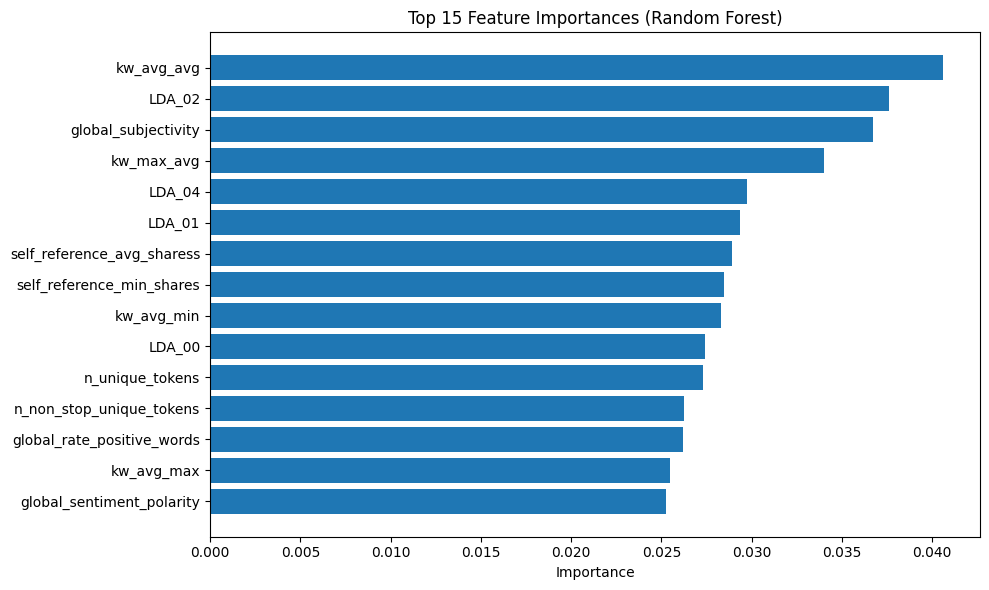

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(feature_df['Feature'][:15][::-1], feature_df['Importance'][:15][::-1])
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()

## 5. 4번에서 전처리 방법 약간 다르게 (외엔 다 같게)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. 데이터 로드
train_df = pd.read_csv("train.csv")

# 2. 전처리 함수
def preprocessing(df):
    df = df.copy()

    # 수치형 결측치 처리
    numeric_fill_median = [
        'n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words',
        'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'
    ]
    for col in numeric_fill_median:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())

    # 감성, 키워드, 공유수 관련 → log 변환 전 처리
    for col in ['title_sentiment_polarity', 'abs_title_sentiment_polarity']:
        df[col] = df[col].fillna(0.0)

    for col in ['self_reference_avg_sharess', 'num_keywords']:
        df[col] = df[col].fillna(df[col].mean())
        df[col] = np.log1p(df[col])  # log(x + 1)

    # kw_ 계열 → 평균 대체
    kw_cols = [col for col in df.columns if col.startswith('kw_')]
    for col in kw_cols:
        df[col] = df[col].fillna(df[col].mean())

    # 범주형 결측치 처리 + 파생
    df['data_channel'] = df['data_channel'].fillna('Other')
    df['weekday'] = df['weekday'].fillna(df['weekday'].mode()[0])
    df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

    df = pd.get_dummies(df, columns=['data_channel', 'weekday'], prefix=['channel', 'day'])

    # 불필요 열 제거
    df = df.drop(columns=['id', 'url', 'timedelta', 'shares'], errors='ignore')

    # 남은 결측치 최종 정리
    df = df.dropna()

    return df

# 3. 전처리 적용
train_df_clean = preprocessing(train_df)

# 4. 특성 / 타겟 분리
X = train_df_clean.drop(columns=['y'])
y = train_df_clean['y']

# 5. 표준화 (정규화)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# 6. 학습/검증 분할
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 7. 하이퍼파라미터 그리드 설정
param_grid = {
    'n_estimators': [205, 207],
    'max_depth': [21, 20, None],
    'min_samples_split': [9, 10, 11],
    'max_features': ['sqrt', 'log2']
}

# 8. 모델 학습 (GridSearchCV)
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# 9. 평가
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_val)
y_prob = best_model.predict_proba(X_val)[:, 1]

acc = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)
final_score = (acc + f1 + auc) / 3

# 10. 결과 출력
print("Best Parameters:", grid_search.best_params_)
print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
print(f"Final Score (avg): {final_score:.4f}")

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters: {'max_depth': 21, 'max_features': 'sqrt', 'min_samples_split': 10, 'n_estimators': 205}
Accuracy: 0.6720, F1 Score: 0.6588, AUC: 0.7437
Final Score (avg): 0.6915


## 5번에서 threshold 비교하기

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. 데이터 로드
train_df = pd.read_csv("train.csv")

# 2. 전처리 함수
def preprocessing(df):
    df = df.copy()

    numeric_fill_median = [
        'n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words',
        'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'
    ]
    for col in numeric_fill_median:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())

    for col in ['title_sentiment_polarity', 'abs_title_sentiment_polarity']:
        df[col] = df[col].fillna(0.0)

    for col in ['self_reference_avg_sharess', 'num_keywords']:
        df[col] = df[col].fillna(df[col].mean())
        df[col] = np.log1p(df[col])

    kw_cols = [col for col in df.columns if col.startswith('kw_')]
    for col in kw_cols:
        df[col] = df[col].fillna(df[col].mean())

    df['data_channel'] = df['data_channel'].fillna('Other')
    df['weekday'] = df['weekday'].fillna(df['weekday'].mode()[0])
    df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

    df = pd.get_dummies(df, columns=['data_channel', 'weekday'], prefix=['channel', 'day'])
    df = df.drop(columns=['id', 'url', 'timedelta', 'shares'], errors='ignore')
    df = df.dropna()

    return df

# 3. 전처리 적용
train_df_clean = preprocessing(train_df)

# 4. 특성 / 타겟 분리
X = train_df_clean.drop(columns=['y'])
y = train_df_clean['y']

# 5. 학습/검증 분할
X_train_raw, X_val_raw, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 스케일링
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns)
X_val = pd.DataFrame(scaler.transform(X_val_raw), columns=X.columns)

# 7. 하이퍼파라미터 그리드 설정
param_grid = {
    'n_estimators': [200, 203],
    'max_depth': [23, 22, 21, None],
    'min_samples_split': [9, 10, 11],
    'max_features': ['sqrt', 'log2']
}

# 8. 모델 학습
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# 9. 베스트 모델 및 예측 확률
best_model = grid_search.best_estimator_
y_prob = best_model.predict_proba(X_val)[:, 1]  # 클래스 1의 확률

# 10. threshold별 평가 함수 정의
def evaluate_with_threshold(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    final_score = (acc + f1 + auc) / 3
    print(f"\n🔎 Threshold = {threshold}")
    print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
    print(f"Final Score (avg): {final_score:.4f}")

# 11. 결과 출력
print("\n📌 Best Parameters from GridSearchCV:")
print(grid_search.best_params_)

for threshold in [0.48, 0.5, 0.52]:
    evaluate_with_threshold(y_val, y_prob, threshold)

Fitting 3 folds for each of 48 candidates, totalling 144 fits

📌 Best Parameters from GridSearchCV:
{'max_depth': 22, 'max_features': 'log2', 'min_samples_split': 10, 'n_estimators': 200}

🔎 Threshold = 0.48
Accuracy: 0.6788, F1 Score: 0.6846, AUC: 0.7520
Final Score (avg): 0.7051

🔎 Threshold = 0.5
Accuracy: 0.6834, F1 Score: 0.6729, AUC: 0.7520
Final Score (avg): 0.7028

🔎 Threshold = 0.52
Accuracy: 0.6834, F1 Score: 0.6463, AUC: 0.7520
Final Score (avg): 0.6939



🔍 Top 15 Important Features:
                       Feature  Importance
19                  kw_avg_avg    0.040796
20   self_reference_min_shares    0.038838
25                      LDA_02    0.034208
22  self_reference_avg_sharess    0.034039
18                  kw_max_avg    0.032765
28         global_subjectivity    0.032287
21   self_reference_max_shares    0.029855
29   global_sentiment_polarity    0.028976
9         average_token_length    0.028272
24                      LDA_01    0.027556
30  global_rate_positive_words    0.027059
13                  kw_avg_min    0.026982
27                      LDA_04    0.026959
16                  kw_avg_max    0.026573
4     n_non_stop_unique_tokens    0.025879


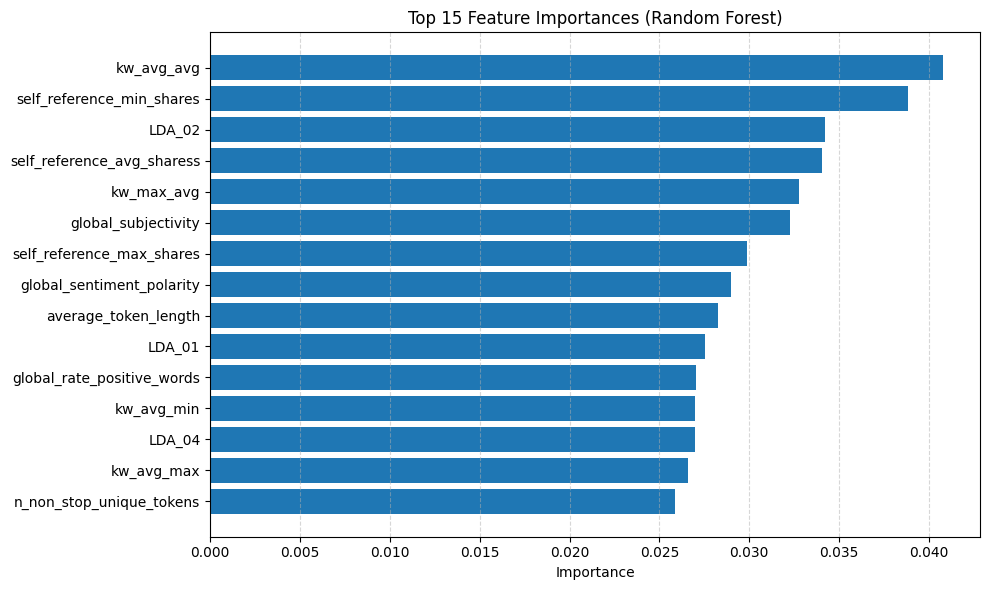

In [ ]:
# 12. Feature Importance 분석
import matplotlib.pyplot as plt
import pandas as pd

# 중요도 추출
importances = best_model.feature_importances_
feature_names = X.columns  # 원본 피처명 기준

# 데이터프레임 생성 및 정렬
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 상위 15개 출력
print("\n🔍 Top 15 Important Features:")
print(feature_df.head(15))

# 시각화
plt.figure(figsize=(10, 6))
top_n = 15
plt.barh(feature_df['Feature'][:top_n][::-1], feature_df['Importance'][:top_n][::-1])
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances (Random Forest)")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6번에서 파라미터 변경

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. 데이터 로드
train_df = pd.read_csv("train.csv")

# 2. 전처리 함수
def preprocessing(df):
    df = df.copy()

    numeric_fill_median = [
        'n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words',
        'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'
    ]
    for col in numeric_fill_median:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())

    for col in ['title_sentiment_polarity', 'abs_title_sentiment_polarity']:
        df[col] = df[col].fillna(0.0)

    for col in ['self_reference_avg_sharess', 'num_keywords']:
        df[col] = df[col].fillna(df[col].mean())
        df[col] = np.log1p(df[col])

    kw_cols = [col for col in df.columns if col.startswith('kw_')]
    for col in kw_cols:
        df[col] = df[col].fillna(df[col].mean())

    df['data_channel'] = df['data_channel'].fillna('Other') # 결측치가 있는 부분은 버리고 해보기
    df['weekday'] = df['weekday'].fillna(df['weekday'].mode()[0])
    df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

    df = pd.get_dummies(df, columns=['data_channel', 'weekday'], prefix=['channel', 'day'])
    df = df.drop(columns=['id', 'url', 'timedelta', 'shares'], errors='ignore')
    df = df.dropna()

    return df

# 3. 전처리 적용
train_df_clean = preprocessing(train_df)

# 4. 특성 / 타겟 분리
X = train_df_clean.drop(columns=['y'])
y = train_df_clean['y']

# 5. 학습/검증 분할
X_train_raw, X_val_raw, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. 스케일링
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns)
X_val = pd.DataFrame(scaler.transform(X_val_raw), columns=X.columns)

# 7. 하이퍼파라미터 그리드 설정
param_grid = {
    'n_estimators': [180, 190, 200, 203],
    'max_depth': [23, 22, 21, None],
    'min_samples_split': [9, 10, 11],
    'max_features': ['sqrt', 'log2']
}

# 8. 모델 학습
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# 9. 베스트 모델 및 예측 확률
best_model = grid_search.best_estimator_
y_prob = best_model.predict_proba(X_val)[:, 1]  # 클래스 1의 확률

# 10. threshold별 평가 함수 정의
def evaluate_with_threshold(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    final_score = (acc + f1 + auc) / 3
    print(f"\n🔎 Threshold = {threshold}")
    print(f"Accuracy: {acc:.4f}, F1 Score: {f1:.4f}, AUC: {auc:.4f}")
    print(f"Final Score (avg): {final_score:.4f}")

# 11. 결과 출력
print("\n📌 Best Parameters from GridSearchCV:")
print(grid_search.best_params_)

for threshold in [0.48, 0.49, 0.5]:
    evaluate_with_threshold(y_val, y_prob, threshold)

Fitting 3 folds for each of 96 candidates, totalling 288 fits


KeyboardInterrupt: 

## Prediction.csv

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# 1. 데이터 로드
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

# 2. 전처리 함수 정의
def preprocessing(df, drop_na=True):
    df = df.copy()

    numeric_fill_median = [
        'n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words',
        'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'
    ]
    for col in numeric_fill_median:
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())

    for col in ['title_sentiment_polarity', 'abs_title_sentiment_polarity']:
        df[col] = df[col].fillna(0.0)

    for col in ['self_reference_avg_sharess', 'num_keywords']:
        df[col] = df[col].fillna(df[col].mean())
        df[col] = np.log1p(df[col])

    kw_cols = [col for col in df.columns if col.startswith('kw_')]
    for col in kw_cols:
        df[col] = df[col].fillna(df[col].mean())

    df['data_channel'] = df['data_channel'].fillna('Other')
    df['weekday'] = df['weekday'].fillna(df['weekday'].mode()[0])
    df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

    df = pd.get_dummies(df, columns=['data_channel', 'weekday'], prefix=['channel', 'day'])

    df = df.drop(columns=['id', 'url', 'timedelta', 'shares'], errors='ignore')

    if drop_na:
        df = df.dropna()

    return df

# 3. 전처리 적용
train_clean = preprocessing(train_df, drop_na=True)
test_clean = preprocessing(test_df, drop_na=False)

# 4. X, y 분리
X_train = train_clean.drop(columns=['y'])
y_train = train_clean['y']

# 5. 스케일링
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(test_clean[X_train.columns]), columns=X_train.columns)

# 6. 최적 모델 학습 (하이퍼파라미터: max_depth=22, max_features='log2', min_samples_split=10, n_estimators=200)
model = RandomForestClassifier(
    max_depth=22,
    max_features='log2',
    min_samples_split=10,
    n_estimators=200,
    random_state=42
)
model.fit(X_train_scaled, y_train)

# 7. 예측 (threshold 0.48 적용)
y_prob_test = model.predict_proba(X_test_scaled)[:, 1]
y_pred_test = (y_prob_test >= 0.48).astype(int)

# 8. 결과 저장
test_result = test_df.copy()
test_result['y_predict'] = y_pred_test
test_result['y_prob'] = y_prob_test
test_result.to_csv('prediction.csv', index=False)

# 9. 다운로드
from google.colab import files
files.download('prediction.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>